**EXTRACT TRANSFORM LOAD**

Step 1 - Import

In [47]:
import pandas as pd
import numpy as np

Step 2- Extract

In [48]:
df = pd.read_csv("social_media_engagement_uncleaned_20000.csv")
print(df.shape)
df.head()

(20050, 10)


,post_id,account_id,post_timestamp,platform,content_type,reach,impressions,likes,comments,shares
0,P118244,ACC1107,2025-09-29 13:18:36,TikTok,Reel,2268,4769,111,33.0,5.0
1,P108714,ACC1226,2025-01-12 07:08:52,X,Reel,866,2026,83,9.0,1.0
2,P118171,ACC1005,2025/02/04,TikTok,Reel,1359,1930,62,NaN,30.0
3,P109711,ACC1158,2025-11-25 03:18:15,TikTok,Video,1894,NaN,132,10.0,8.0
4,P100456,ACC1503,2024-19-45,Instagram,Reel,2018,4709,141,10.0,31.0


INFO() ISNULL() DUPLICATED().SUM() DESCRIBE()

In [49]:
df.info()

df.isnull().sum()

df.duplicated().sum()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20050 entries, 0 to 20049
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   post_id         20050 non-null  object 
 1   account_id      19950 non-null  object 
 2   post_timestamp  19870 non-null  object 
 3   platform        19828 non-null  object 
 4   content_type    19790 non-null  object 
 5   reach           19750 non-null  object 
 6   impressions     19800 non-null  object 
 7   likes           19770 non-null  object 
 8   comments        19809 non-null  float64
 9   shares          19790 non-null  float64
dtypes: float64(2), object(8)
memory usage: 1.5+ MB


,comments,shares
count,1.980900e+04,1.979000e+04
mean,2.239309e+05,3.463862e+05
std,1.050673e+07,1.496370e+07
min,-4.690000e+02,-4.960000e+02
25%,4.000000e+00,6.000000e+00
50%,1.100000e+01,1.400000e+01
75%,2.200000e+01,3.000000e+01
max,8.287335e+08,8.240351e+08


Step 4 – Create a copy

In [50]:
df_clean = df.copy()

Step 5 – Remove duplicate records

In [51]:
df_clean.drop_duplicates(inplace=True)

df_clean.drop_duplicates(subset="post_id", keep="first", inplace=True)

Step 6 – Clean column names

In [52]:
df_clean.columns = df_clean.columns.str.strip().str.lower()

Step 7 – Clean categorical values

In [53]:
df_clean["platform"] = df_clean["platform"].astype("string").str.strip().str.lower()

df_clean["content_type"] = df_clean["content_type"].astype("string").str.strip().str.lower()

df_clean["platform"] = df_clean["platform"].replace({
    "ig": "instagram",
    "insta gram": "instagram",
    "twitter": "x"
})

df_clean["content_type"] = df_clean["content_type"].replace({
    "photo": "image",
    "vid": "video",
    "reels": "reel",
    "multi-image": "carousel",
    "status": "text",
    "stories": "story"
})

Step 8 – Convert numeric columns

In [54]:
numeric_cols = ["reach", "impressions", "likes", "comments", "shares"]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype("string").str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )

Step 9 – Convert date column

In [55]:
df_clean["post_timestamp"] = pd.to_datetime(
    df_clean["post_timestamp"],
    format="mixed",
    errors="coerce",
    dayfirst=True
)

Step 10 – Handle invalid values

In [56]:
for col in numeric_cols:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

Step 11 – Handle missing values

In [57]:
df_clean.dropna(
    subset=["post_id", "post_timestamp", "platform", "content_type"],
    inplace=True
)

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

Step 12 – Load

In [58]:
df_clean.to_csv("social_media_engagement_cleaned.csv", index=False)

Step 13 – Final validation

In [59]:
print("Final Shape:", df_clean.shape)

print("Missing Values:")
print(df_clean.isnull().sum())

print("Duplicate Rows:", df_clean.duplicated().sum())

df_clean.head()

Final Shape: (19221, 10)
Missing Values:
post_id            0
account_id        95
post_timestamp     0
platform           0
content_type       0
reach              0
impressions        0
likes              0
comments           0
shares             0
dtype: int64
Duplicate Rows: 0


,post_id,account_id,post_timestamp,platform,content_type,reach,impressions,likes,comments,shares
0,P118244,ACC1107,2025-09-29 13:18:36,tiktok,reel,2268,4769,111,33.0,5.0
1,P108714,ACC1226,2025-01-12 07:08:52,x,reel,866,2026,83,9.0,1.0
2,P118171,ACC1005,2025-02-04 00:00:00,tiktok,reel,1359,1930,62,11.0,30.0
3,P109711,ACC1158,2025-11-25 03:18:15,tiktok,video,1894,2385,132,10.0,8.0
5,P118949,ACC1101,2024-07-29 18:53:00,tiktok,story,5244,8486,73,17.0,88.0


Final check

In [60]:
print(df_clean.shape)
print(df_clean.isnull().sum())
print(df_clean.duplicated().sum())
print(df_clean.dtypes)

(19221, 10)
post_id            0
account_id        95
post_timestamp     0
platform           0
content_type       0
reach              0
impressions        0
likes              0
comments           0
shares             0
dtype: int64
0
post_id                   object
account_id                object
post_timestamp    datetime64[ns]
platform          string[python]
content_type      string[python]
reach                      Int64
impressions                Int64
likes                      Int64
comments                 Float64
shares                   Float64
dtype: object


**EXPLORATORY DATA ANALYSIS**

1. Dataset shape

In [61]:
df.shape

(20050, 10)

2. First 5 records

In [62]:
df.head()

,post_id,account_id,post_timestamp,platform,content_type,reach,impressions,likes,comments,shares
0,P118244,ACC1107,2025-09-29 13:18:36,TikTok,Reel,2268,4769,111,33.0,5.0
1,P108714,ACC1226,2025-01-12 07:08:52,X,Reel,866,2026,83,9.0,1.0
2,P118171,ACC1005,2025/02/04,TikTok,Reel,1359,1930,62,NaN,30.0
3,P109711,ACC1158,2025-11-25 03:18:15,TikTok,Video,1894,NaN,132,10.0,8.0
4,P100456,ACC1503,2024-19-45,Instagram,Reel,2018,4709,141,10.0,31.0


3. Last 5 records

In [63]:
df.tail()

,post_id,account_id,post_timestamp,platform,content_type,reach,impressions,likes,comments,shares
20045,P116432,ACC1405,2025-09-14 18:20:36,YouTube,Reel,1002,1383,76,2.0,13.0
20046,P108964,ACC1155,2025-09-27 00:35:22,X,Carousel,396,661,34,2.0,4.0
20047,P105944,ACC1494,2024-07-04 09:33:07,Instagram,Image,6539,17655,452,41.0,89.0
20048,P105327,ACC1037,2024/06/28,TikTok,Image,1278,1758,151,4.0,25.0
20049,P115305,ACC1523,2025-12-15 00:18:22,YouTube,Text,518,-133,14,2.0,9.0


4. Dataset information

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20050 entries, 0 to 20049
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   post_id         20050 non-null  object 
 1   account_id      19950 non-null  object 
 2   post_timestamp  19870 non-null  object 
 3   platform        19828 non-null  object 
 4   content_type    19790 non-null  object 
 5   reach           19750 non-null  object 
 6   impressions     19800 non-null  object 
 7   likes           19770 non-null  object 
 8   comments        19809 non-null  float64
 9   shares          19790 non-null  float64
dtypes: float64(2), object(8)
memory usage: 1.5+ MB


5. Statistical summary

In [65]:
df.describe()

,comments,shares
count,1.980900e+04,1.979000e+04
mean,2.239309e+05,3.463862e+05
std,1.050673e+07,1.496370e+07
min,-4.690000e+02,-4.960000e+02
25%,4.000000e+00,6.000000e+00
50%,1.100000e+01,1.400000e+01
75%,2.200000e+01,3.000000e+01
max,8.287335e+08,8.240351e+08


6. Unique values

In [66]:
df.nunique()

,0
post_id,19900
account_id,600
post_timestamp,19732
platform,21
content_type,25
reach,5915
impressions,8520
likes,1110
comments,250
shares,325


3. Step 3 – Categorical Analysis

In [67]:
df["platform"].value_counts()

,count
platform,
Instagram,5599
Facebook,4181
TikTok,3777
YouTube,3134
X,2246
Insta gram,81
IG,79
FaceBook,72
Tik Tok,63


In [68]:
df["content_type"].value_counts()

,count
content_type,
Video,4432
Image,3799
Reel,3450
Story,2665
Carousel,2656
Text,1896
vid,91
VIDEO,88
video,68


4. Step 4 – Numerical columns

In [69]:
df[["reach", "impressions", "likes", "comments", "shares"]].describe()

,comments,shares
count,1.980900e+04,1.979000e+04
mean,2.239309e+05,3.463862e+05
std,1.050673e+07,1.496370e+07
min,-4.690000e+02,-4.960000e+02
25%,4.000000e+00,6.000000e+00
50%,1.100000e+01,1.400000e+01
75%,2.200000e+01,3.000000e+01
max,8.287335e+08,8.240351e+08


5. Verify our cleaned dataset

In [70]:
df_clean["platform"].value_counts()

,count
platform,
instagram,5679
facebook,4246
tiktok,3718
youtube,3144
x,2268
tik tok,109
you tube,57


**6.Univariate analysis**

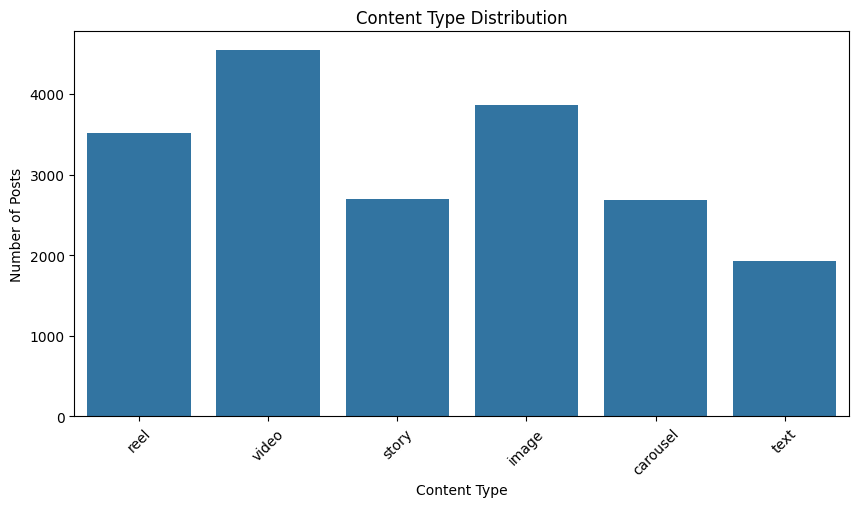

In [71]:
plt.figure(figsize=(10,5))

sns.countplot(data=df_clean, x="content_type")

plt.title("Content Type Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)

plt.show()

**Insight:**
- Video content has the highest number of posts (4,547).
- Text content has the lowest number of posts (1,923).
- This indicates that video-based content is more frequently published in the dataset.

**Recommendation:**
- Continue analyzing video content performance to understand its engagement potential.
- Experiment with less frequently used content types to identify new opportunities.
- Maintain a balanced content strategy based on audience response.

7. Checking content types

In [72]:
df_clean["content_type"].value_counts()

,count
content_type,
video,4547
image,3864
reel,3511
story,2691
carousel,2685
text,1923


8. Numerical Univariate Analysis

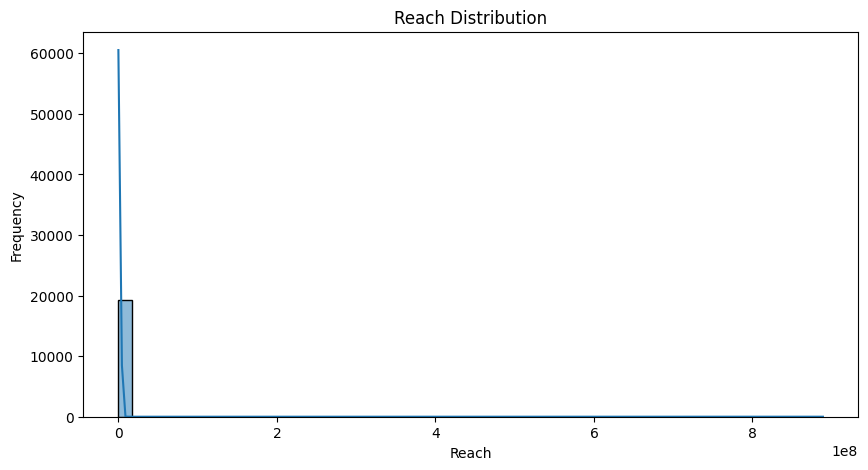

In [73]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df_clean, x="reach", bins=50, kde=True)

plt.title("Reach Distribution")
plt.xlabel("Reach")
plt.ylabel("Frequency")

plt.show()

**Insight:**
- The Reach distribution is highly positively skewed (right-skewed).
- Most social media posts receive relatively low reach.
- A small number of posts receive extremely high reach.
- The distribution indicates that reach is not evenly distributed across all posts.
- The KDE curve helps visualize the overall distribution pattern.

 **Recommendation:**
- Analyze high-reach posts to identify successful content strategies.
- Focus on improving the reach of posts that currently receive lower visibility.
- Use median reach instead of relying only on mean reach because the distribution is highly skewed.
- Develop content strategies based on patterns observed in successful posts.

9. Check Skewness

In [74]:
df_clean["reach"].skew()

np.float64(45.02115477650052)

10. IQR Method – Outlier Detection

In [75]:
Q1 = df_clean["reach"].quantile(0.25)
Q3 = df_clean["reach"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 718.0
Q3: 2270.0
IQR: 1552.0


11. Calculate Lower Bound & Upper Bound

In [76]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -1610.0
Upper Bound: 4598.0


12. Count Outliers

In [77]:
outliers = df_clean[
    (df_clean["reach"] < lower_bound) |
    (df_clean["reach"] > upper_bound)
]

print("Total Outliers:", len(outliers))

Total Outliers: 1374


13. Box Plot

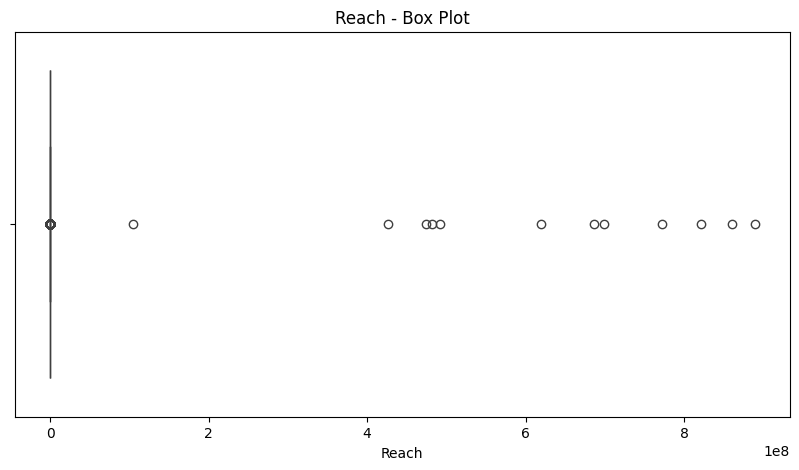

In [78]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df_clean["reach"])
plt.title("Reach - Box Plot")
plt.xlabel("Reach")
plt.show()

**Insight:**
- The box plot shows that the Reach variable contains several potential outliers.
- The distribution is highly right-skewed, with extreme values on the higher side.
- Most posts have reach values within a relatively smaller range.
- A small number of posts have exceptionally high reach compared to the majority.
- The IQR method identified 1,374 potential outliers in the Reach column.

**Recommendation:**
- Investigate high-reach posts to identify the factors behind their performance.
- Avoid removing outliers without checking whether they represent genuine viral posts.
- Use median and IQR to understand typical reach more accurately.
- Develop strategies to improve reach among lower-performing posts.

**Bivariate Analysis**

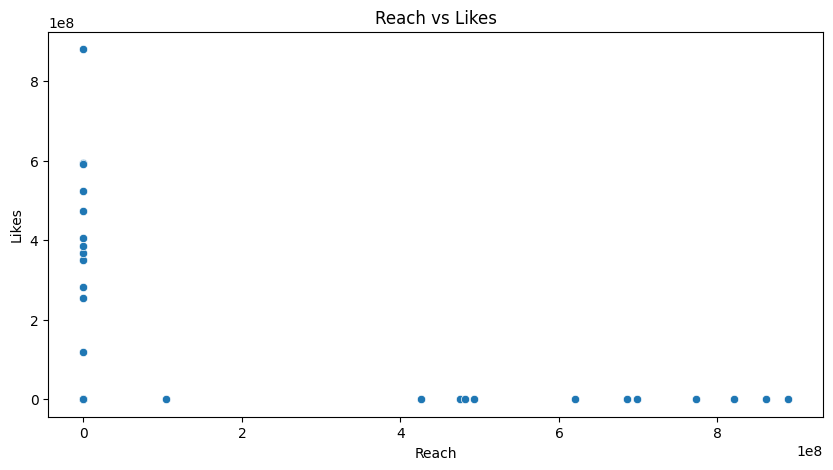

In [79]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_clean,
    x="reach",
    y="likes"
)
plt.title("Reach vs Likes")
plt.xlabel("Reach")
plt.ylabel("Likes")
plt.show()

**Insight:**
- The scatter plot illustrates the relationship between post reach and likes.
- It helps identify whether posts with higher reach also receive more likes.
- The distribution of points shows variations in likes across different reach levels.
- Posts with high reach but comparatively low likes may indicate lower audience interaction.
- The overall relationship (positive, negative or weak) should be confirmed from the actual point pattern.

**Recommendation:**
- Analyze posts that achieve high reach and high likes to identify successful content strategies.
- Improve content quality and relevance to increase likes among high-reach posts.
- Monitor both reach and likes to evaluate content performance.
- Identify posts with high reach but low likes and investigate why audiences are not interacting.

Correlation

In [80]:
correlation = df_clean[[
    "reach", "likes", "comments", "shares", "impressions"
]].corr()

print(correlation)

                reach     likes  comments    shares  impressions
reach        1.000000 -0.000541 -0.000510 -0.000553    -0.000543
likes       -0.000541  1.000000 -0.000496 -0.000539    -0.000530
comments    -0.000510 -0.000496  1.000000 -0.000508    -0.000499
shares      -0.000553 -0.000539 -0.000508  1.000000    -0.000540
impressions -0.000543 -0.000530 -0.000499 -0.000540     1.000000


Heatmap

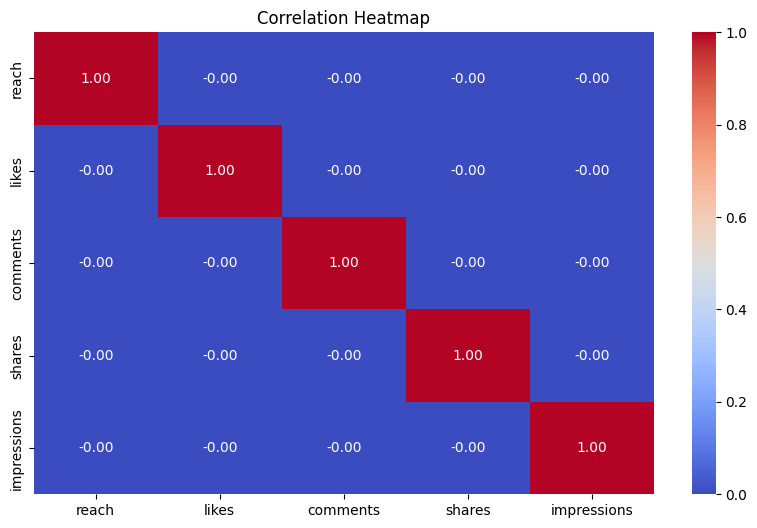

In [81]:
plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

**Insight:**
- The correlation heatmap represents the relationship between numerical variables such as reach, impressions, likes, comments and shares.
- Positive correlation indicates that two variables tend to increase together.
- Negative correlation indicates that one variable tends to increase while the other decreases.
- Values closer to +1 indicate a strong positive correlation.
- Values closer to -1 indicate a strong negative correlation.
- Values closer to 0 indicate a weak linear relationship.
- The heatmap helps identify which social media metrics are strongly related to each other.

**Recommendation:**
- Identify metrics that show strong positive relationships with engagement.
- Use correlated metrics to understand social media performance patterns.
- Focus on improving engagement metrics that show weaker relationships with reach.
- Avoid assuming that correlation means one metric causes another.

**Multivariate Analysis**

In [84]:
multi_analysis = df_clean.groupby(
    ["platform", "content_type"]
)["reach"].mean().reset_index()

print(multi_analysis)

     platform content_type            reach
0    facebook     carousel      1564.589109
1    facebook        image    804822.622951
2    facebook         reel      1561.989218
3    facebook        story      1679.325733
4    facebook         text      1534.081633
5    facebook        video      1539.008089
6   instagram     carousel      1933.162198
7   instagram        image     93105.191638
8   instagram         reel   1266290.330609
9   instagram        story    611929.849614
10  instagram         text   1445616.660808
11  instagram        video    892426.816006
12    tik tok     carousel         2425.875
13    tik tok        image      2357.583333
14    tik tok         reel      2391.736842
15    tik tok        story           2690.3
16    tik tok         text           2531.9
17    tik tok        video           2191.0
18     tiktok     carousel      2425.375899
19     tiktok        image      2259.977027
20     tiktok         reel    1306277.64697
21     tiktok        story      

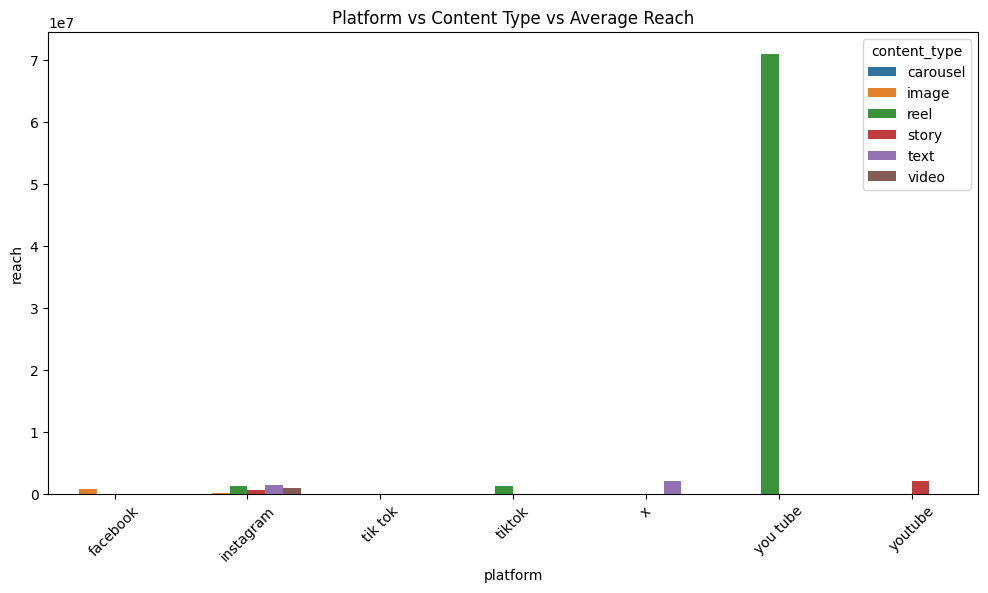

In [85]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=multi_analysis,
    x="platform",
    y="reach",
    hue="content_type"
)

plt.title("Platform vs Content Type vs Average Reach")
plt.xticks(rotation=45)
plt.show()

**Insight:**
- The chart compares the average reach of different content types across social media platforms.
- It helps identify which content types achieve higher average reach on each platform.
- Performance may vary depending on the platform and content type.
- Some content formats may perform better on one platform than on others.
- The comparison helps understand platform-specific content performance.

**Recommendation:**
- Focus on content types that achieve higher average reach on each platform.
- Develop separate content strategies for Instagram, Facebook, TikTok and YouTube.
- Experiment with lower-performing content formats to improve their reach.
- Regularly monitor platform-wise performance to identify changing audience preferences.

**TIMESERIES**

Convert Timestamp

In [86]:
df_clean["post_timestamp"] = pd.to_datetime(
    df_clean["post_timestamp"],
    errors="coerce"
)

Extract Date

In [87]:
df_clean["date"] = df_clean["post_timestamp"].dt.date

Daily Post Count

In [88]:
daily_posts = df_clean.groupby("date")["post_id"].count()

print(daily_posts.head())

date
2024-01-01    24
2024-01-02    19
2024-01-03    27
2024-01-04    35
2024-01-05    30
Name: post_id, dtype: int64


Daily Posts Line Chart

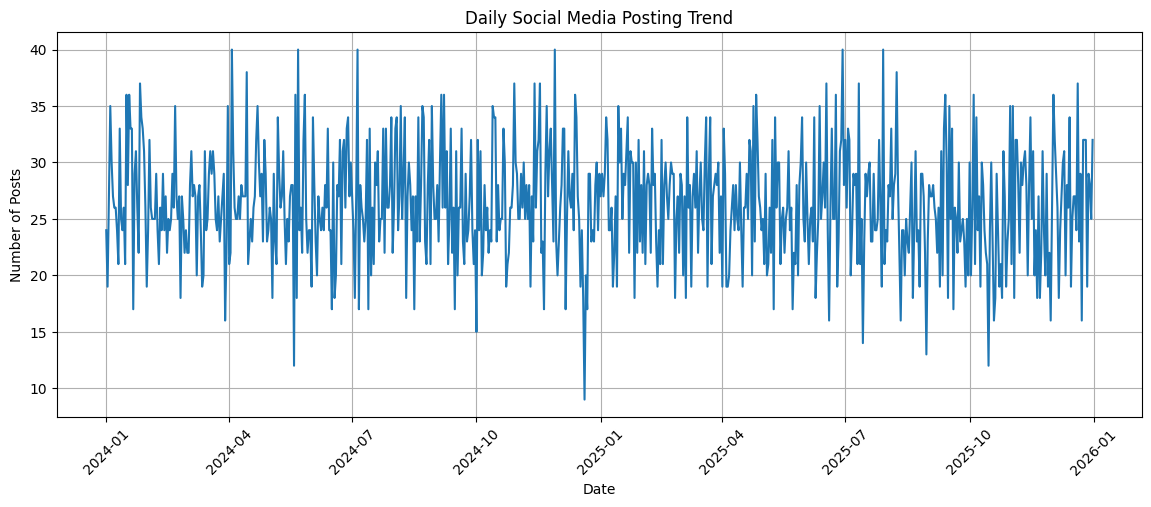

In [89]:
plt.figure(figsize=(14, 5))

plt.plot(daily_posts.index, daily_posts.values)

plt.title("Daily Social Media Posting Trend")
plt.xlabel("Date")
plt.ylabel("Number of Posts")

plt.xticks(rotation=45)
plt.grid(True)
plt.show()

**Insight:**
- The line chart represents the number of social media posts published each day.
- It helps identify daily variations in posting activity.
- Peaks indicate days with higher posting frequency.
- Drops indicate days with lower posting frequency.
- The chart helps identify fluctuations and patterns in social media publishing activity.

**Recommendation:**
- Maintain a consistent daily posting schedule.
- Identify days with lower posting activity and improve content scheduling.
- Plan content calendars based on observed posting patterns.
- Monitor posting frequency to avoid irregular publishing.

7-Day Rolling Average

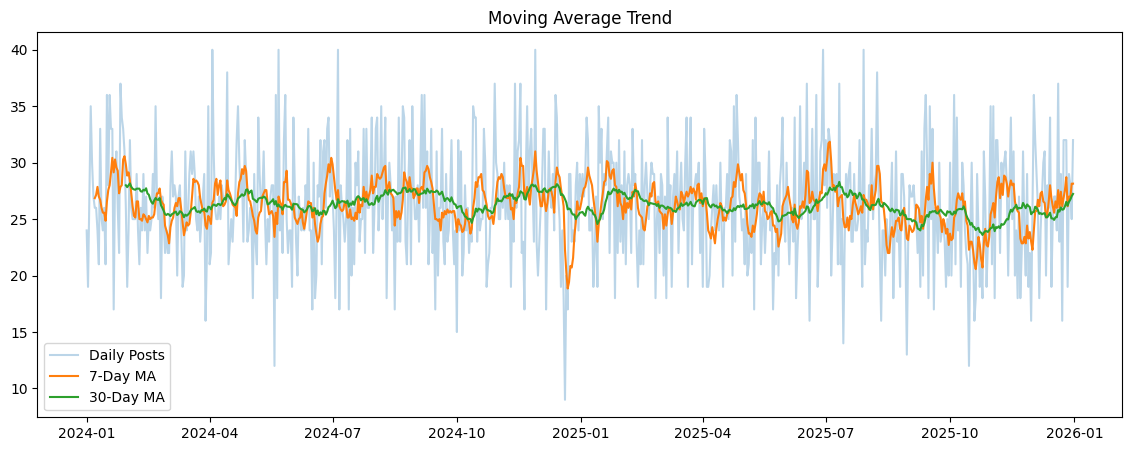

In [91]:
rolling_7d = daily_posts.rolling(window=7).mean()

rolling_30d = daily_posts.rolling(window=30).mean()

plt.figure(figsize=(14, 5))

plt.plot(daily_posts, label="Daily Posts", alpha=0.3)
plt.plot(rolling_7d, label="7-Day MA")
plt.plot(rolling_30d, label="30-Day MA")

plt.legend()
plt.title("Moving Average Trend")
plt.show()

**Insight:**
- The chart compares daily posting activity with 7-day and 30-day moving averages.
- The 7-Day Moving Average highlights short-term changes in posting frequency.
- The 30-Day Moving Average shows the long-term posting trend.
- Moving averages smooth daily fluctuations and make overall trends easier to understand.
- When both moving averages increase, it indicates an upward trend in posting activity.
- When they decrease, it indicates a decline in posting activity.

**Recommendation:**
- Use the 7-day moving average to monitor weekly posting consistency.
- Use the 30-day moving average for long-term content planning.
- Investigate sudden increases or decreases in posting activity.
- Maintain a consistent publishing schedule based on observed trends.

**Hypothesis Testing**

In [92]:
df_clean[["content_type", "likes"]].dtypes

,0
content_type,string[python]
likes,Int64


In [93]:
video_likes = df_clean[df_clean["content_type"] == "video"]["likes"].dropna()

image_likes = df_clean[df_clean["content_type"] == "image"]["likes"].dropna()

print("Video Mean:", video_likes.mean())
print("Image Mean:", image_likes.mean())

print("Video Count:", len(video_likes))
print("Image Count:", len(image_likes))

Video Mean: 274719.5308994942
Image Mean: 122921.48421325051
Video Count: 4547
Image Count: 3864


Perform T-Test

In [94]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    video_likes,
    image_likes,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: 0.6241817116765509
P-Value: 0.5325280369896735


RESULT

In [95]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Video and Image posts have a significant difference in average likes.")
else:
    print("Fail to reject H0")
    print("There is not enough evidence of a significant difference in average likes.")

Fail to reject H0
There is not enough evidence of a significant difference in average likes.


ANOVA

In [96]:
from scipy.stats import f_oneway

groups = [
    df_clean[df_clean["content_type"] == content]["likes"].dropna()
    for content in df_clean["content_type"].unique()
]

f_stat, p_value = f_oneway(*groups)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

F-Statistic: 1.007291337332861
P-Value: 0.4114795263545397


RESULT

In [97]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("At least one content type has a significantly different average likes.")
else:
    print("Fail to reject H0")
    print("No sufficient evidence of a significant difference in average likes.")

Fail to reject H0
No sufficient evidence of a significant difference in average likes.


Paired T-Test

In [98]:
import pandas as pd

data = {
    "Before_Campaign": [120, 150, 100, 180, 130, 160, 110, 140],
    "After_Campaign":  [150, 170, 130, 200, 160, 190, 140, 165]
}

df_paired = pd.DataFrame(data)

print(df_paired)

   Before_Campaign  After_Campaign
0              120             150
1              150             170
2              100             130
3              180             200
4              130             160
5              160             190
6              110             140
7              140             165


In [99]:
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(
    df_paired["Before_Campaign"],
    df_paired["After_Campaign"]
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: -16.594667177241135
P-Value: 7.048086405263122e-07


RESULT

In [100]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("There is a significant difference before and after the campaign.")
else:
    print("Fail to reject H0")
    print("There is no sufficient evidence of a significant difference.")

Reject H0
There is a significant difference before and after the campaign.


Chi-Square Test

In [101]:
contingency_table = pd.crosstab(
    df_clean["platform"],
    df_clean["content_type"]
)

print(contingency_table)

content_type  carousel  image  reel  story  text  video
platform                                               
facebook           606    854   742    614   441    989
instagram          746   1148  1101    778   569   1337
tik tok             16     24    19     20    10     20
tiktok             556    740   660    531   366    865
x                  336    453   397    309   230    543
you tube             8     14     6      8     8     13
youtube            417    631   586    431   299    780


In [102]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 26.975644930801078
P-Value: 0.6245497690243704
Degrees of Freedom: 30


RESULT

In [103]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Platform and Content Type have a significant association.")
else:
    print("Fail to reject H0")
    print("No sufficient evidence of an association.")

Fail to reject H0
No sufficient evidence of an association.


**Key Insights**

Un actual output values base panni final insights write pannanum. Ippo namma analysis-la identify panna mudinja points:
Analysis	Insight
Content Type Analysis	Video content has the highest post count among the cleaned categories.
Reach Distribution	Reach data is highly right-skewed, with a small number of posts having very high reach.
Outlier Analysis	IQR identified 1,374 potential reach outliers.
Time Series	Daily posting trend and 7-day / 30-day moving averages help identify posting patterns.
Hypothesis Testing	Statistical tests help evaluate differences between content types and relationships between platform and content type.

 **Business Recommendations**
1. **Content Strategy**: Compare average engagement across content types and prioritize formats that perform better.
2. **Platform Strategy**: Use platform-wise and content-wise analysis to understand which formats work better on each platform.
3. **Posting Consistency**: Use daily trends and moving averages to plan a consistent posting schedule.
4. **Reach Optimization**: Investigate high-reach posts to identify what contributed to their performance.
5. **Performance Monitoring**: Regularly track likes, comments, shares, reach and engagement rate.